# Framecount analysis — 20261006 hgm

Reads the new `cameraTop_framecount` and `cameraFront_framecount` CSVs, which now have a header with three columns:
- `HarpTimestamp` — global time the frame was received in Bonsai (shared clock across all data streams)
- `CameraTimestamp` — local time from the camera's own clock
- `FrameCounter` — the camera's embedded hardware frame counter

In [2]:
import glob
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

data_dir = Path("../data/20261006 hgm")

In [3]:
top_path = glob.glob(str(data_dir / "cameraTop_framecount*.csv"))[0]
front_path = glob.glob(str(data_dir / "cameraFront_framecount*.csv"))[0]

In [4]:
top_framecount = pd.read_csv(top_path)
front_framecount = pd.read_csv(front_path)

top_framecount["FrameCounterRelative"] = top_framecount["FrameCounter"] - top_framecount["FrameCounter"].iloc[0]
front_framecount["FrameCounterRelative"] = front_framecount["FrameCounter"] - front_framecount["FrameCounter"].iloc[0]

print(f"cameraTop_framecount: {len(top_framecount)} rows")
print(f"cameraFront_framecount: {len(front_framecount)} rows")

cameraTop_framecount: 94894 rows
cameraFront_framecount: 95678 rows


In [5]:
top_framecount.head()

,HarpTimestamp,CameraTimestamp,FrameCounter,FrameCounterRelative
0,2.608772e+06,1769160881,1269314,0
1,2.608772e+06,1769706821,1269315,1
2,2.608772e+06,1770252570,1269316,2
3,2.608772e+06,1770799349,1269317,3
4,2.608772e+06,1771345106,1269318,4


In [6]:
front_framecount.head()

,HarpTimestamp,CameraTimestamp,FrameCounter,FrameCounterRelative
0,2.608772e+06,135051605,1279786,0
1,2.608772e+06,135598336,1279787,1
2,2.608772e+06,136144155,1279788,2
3,2.608772e+06,136689854,1279789,3
4,2.608772e+06,137236701,1279790,4


## Plot frame counter against the shared Harp clock

Unlike the previous dataset, `HarpTimestamp` is a global, shared clock already present in both files, so both cameras can be plotted directly on the same time axis without needing a separate timestamp file.

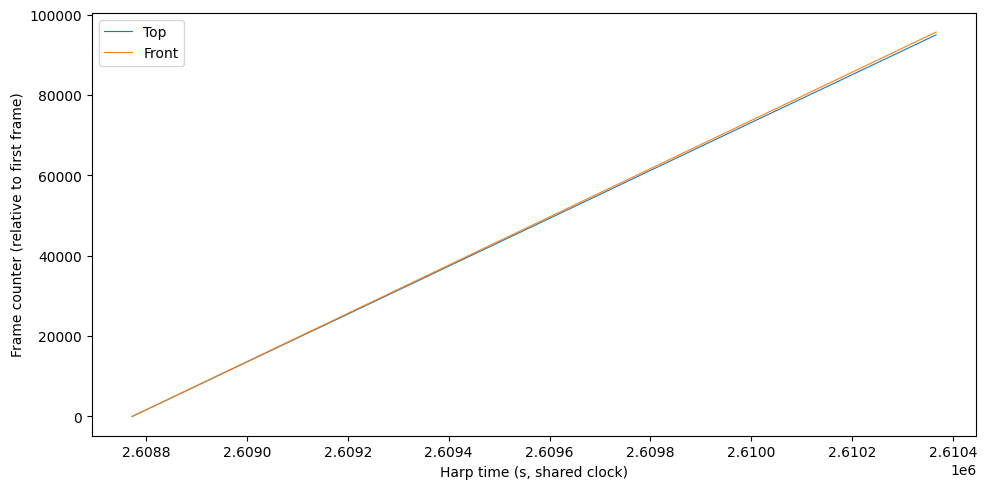

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(top_framecount["HarpTimestamp"], top_framecount["FrameCounterRelative"], label="Top", linewidth=0.8)
ax.plot(front_framecount["HarpTimestamp"], front_framecount["FrameCounterRelative"], label="Front", linewidth=0.8)

ax.set_xlabel("Harp time (s, shared clock)")
ax.set_ylabel("Frame counter (relative to first frame)")
ax.legend()
fig.tight_layout()
plt.show()

## Unwrap `CameraTimestamp` and compare to the Harp clock

`CameraTimestamp` is a 32-bit counter that overflows back to ~0 roughly every 128 s (2³² ticks at a 2²⁵ Hz tick rate = 128 s exactly). Over this ~1594 s recording it wraps ~12 times, so a naive `last - first` is meaningless. Unwrapping it (adding 2³² every time the counter drops) and converting to seconds lets us check it against `HarpTimestamp`, which is already a monotonic shared clock.

In [8]:
CAMERA_TIMESTAMP_WRAP = 2**32
CAMERA_TIMESTAMP_HZ = 2**25  # tick rate implied by the ~128 s wrap period


def unwrap_camera_timestamp(raw):
    raw = raw.to_numpy().astype(np.int64)
    wraps = np.where(np.diff(raw) < 0, CAMERA_TIMESTAMP_WRAP, 0)
    offsets = np.concatenate([[0], np.cumsum(wraps)])
    return raw + offsets


top_framecount["CameraTimestampUnwrapped"] = unwrap_camera_timestamp(top_framecount["CameraTimestamp"])
front_framecount["CameraTimestampUnwrapped"] = unwrap_camera_timestamp(front_framecount["CameraTimestamp"])

top_framecount["CameraTimestampRelative"] = (
    top_framecount["CameraTimestampUnwrapped"] - top_framecount["CameraTimestampUnwrapped"].iloc[0]
)
front_framecount["CameraTimestampRelative"] = (
    front_framecount["CameraTimestampUnwrapped"] - front_framecount["CameraTimestampUnwrapped"].iloc[0]
)

In [9]:
for name, df in [("Top", top_framecount), ("Front", front_framecount)]:
    harp_elapsed = df["HarpTimestamp"].iloc[-1] - df["HarpTimestamp"].iloc[0]
    camera_elapsed = df["CameraTimestampRelative"].iloc[-1] / CAMERA_TIMESTAMP_HZ

    print(f"--- {name} ---")
    print(f"Harp elapsed:       {harp_elapsed:.6f} s")
    print(f"Camera elapsed:     {camera_elapsed:.6f} s (unwrapped)")
    print(f"Difference:         {camera_elapsed - harp_elapsed:.6f} s")
    print()

--- Top ---
Harp elapsed:       1594.533024 s
Camera elapsed:     1594.398593 s (unwrapped)
Difference:         -0.134431 s

--- Front ---
Harp elapsed:       1594.532000 s
Camera elapsed:     1594.470153 s (unwrapped)
Difference:         -0.061847 s



## Time slider + play button: show the most recent frame from each camera

Frames are fetched on demand via `cv2`'s random-access seek (no preloading/caching of the videos) — moving the slider or hitting play looks up, for each camera independently, the most recent frame at or before the current time (using `CameraTimestampRelative`) and updates the display in place.

The play button advances at a target of 60 fps, but actual playback will likely run slower — seeking+decoding both cameras takes a few ms each, plus render/display overhead on top, so treat this as a scrubbing/review tool rather than real-time video playback.

In [10]:
TARGET_FPS = 60.0

top_video_path = glob.glob(str(data_dir / "videoTop*.avi"))[0]
front_video_path = glob.glob(str(data_dir / "videoFront*.avi"))[0]

cap_top = cv2.VideoCapture(top_video_path)
cap_front = cv2.VideoCapture(front_video_path)

top_time_s = (top_framecount["CameraTimestampRelative"] / CAMERA_TIMESTAMP_HZ).to_numpy()
front_time_s = (front_framecount["CameraTimestampRelative"] / CAMERA_TIMESTAMP_HZ).to_numpy()


def latest_idx(time_s, t):
    idx = np.searchsorted(time_s, t, side="right") - 1
    return int(np.clip(idx, 0, len(time_s) - 1))


def get_frame(cap, idx):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    _, frame = cap.read()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


# Build the figure once; each update mutates the existing image/title artists
# instead of recreating the figure, which is much faster for playback.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im_top = axes[0].imshow(get_frame(cap_top, 0))
axes[0].axis("off")
title_top = axes[0].set_title("")
im_front = axes[1].imshow(get_frame(cap_front, 0))
axes[1].axis("off")
title_front = axes[1].set_title("")
fig.tight_layout()
plt.close(fig)


def show_frame_at_step(step):
    t = step / TARGET_FPS
    idx_top = latest_idx(top_time_s, t)
    idx_front = latest_idx(front_time_s, t)

    im_top.set_data(get_frame(cap_top, idx_top))
    title_top.set_text(f"Top (frame {idx_top}, t={top_time_s[idx_top]:.3f}s)")
    im_front.set_data(get_frame(cap_front, idx_front))
    title_front.set_text(f"Front (frame {idx_front}, t={front_time_s[idx_front]:.3f}s)")
    display(fig)


max_t = max(top_time_s[-1], front_time_s[-1])
n_steps = int(max_t * TARGET_FPS) + 1

slider = widgets.IntSlider(min=0, max=n_steps - 1, step=1, value=0, description="frame", layout=widgets.Layout(width="700px"))
play = widgets.Play(min=0, max=n_steps - 1, step=1, interval=int(1000 / TARGET_FPS))
widgets.jslink((play, "value"), (slider, "value"))

out = widgets.interactive_output(show_frame_at_step, {"step": slider})
display(widgets.HBox([play, slider]), out)

Output()